### the control countries list

In [1]:
#Using the country names in word bank as the standard, describe the country names of OECD and natrue_index
nature_index_50 = ['China','United States','Germany','United Kingdom','Japan','France','Korea, Rep.','Canada','India','Switzerland',
                   'Australia','Italy','Spain','Netherlands','Sweden','Israel','Singapore','Denmark','Belgium','Taiwan','Austria','Russian Federation',
                   'Poland','Brazil','Finland','Czechia','Norway','Saudi Arabia','Portugal','Iran, Islamic Rep.','Chile','Ireland',
                   'New Zealand','Turkiye','South Africa','Greece','Mexico','Hungary','Argentina','Thailand','Slovenia','Iceland',
                   'Pakistan','United Arab Emirates','Estonia','Ukraine','Luxembourg','Viet Nam','Croatia','Romania']

oecd_memebers = ['Austria','Belgium','Czechia','Denmark','Estonia','Finland','France','Germany','Greece','Hungary','Iceland','Ireland',
                 'Italy','Latvia','Lithuania','Luxembourg','Netherlands','Norway','Poland','Portugal','Slovak Republic','Slovenia','Spain','Sweden', 
                 'Switzerland','Turkiye','United Kingdom','Canada','Chile','Colombia','Costa Rica','Mexico','United States','Australia','Japan',
                 'Korea, Rep.','New Zealand','Israel']

european_countries = ['Bulgaria','Cyprus','Latvia','Malta']

In [ ]:
import pandas as pd
pd.read_csv('')

In [2]:
# using the insterseation between nature_index_50 and oecd_memebers as control countries
nature_index_50_upper = [item.upper() for item in nature_index_50]
oecd_memebers_upper = [item.upper() for item in oecd_memebers]
european_countries_upper = [item.upper() for item in european_countries]
control_countries = set(nature_index_50_upper).union(set(oecd_memebers_upper))
control_countries = control_countries.union(set(european_countries_upper))
print(len(control_countries))
str(set(list(control_countries)))

58


"{'SINGAPORE', 'SPAIN', 'GREECE', 'LATVIA', 'FINLAND', 'SAUDI ARABIA', 'CROATIA', 'NEW ZEALAND', 'CHINA', 'UNITED STATES', 'AUSTRIA', 'NORWAY', 'PAKISTAN', 'THAILAND', 'RUSSIAN FEDERATION', 'MALTA', 'INDIA', 'SWEDEN', 'SOUTH AFRICA', 'IRELAND', 'FRANCE', 'LITHUANIA', 'SWITZERLAND', 'ISRAEL', 'HUNGARY', 'JAPAN', 'COSTA RICA', 'SLOVAK REPUBLIC', 'IRAN, ISLAMIC REP.', 'ITALY', 'LUXEMBOURG', 'DENMARK', 'MEXICO', 'GERMANY', 'BELGIUM', 'VIET NAM', 'ROMANIA', 'BULGARIA', 'NETHERLANDS', 'AUSTRALIA', 'UNITED KINGDOM', 'ICELAND', 'CHILE', 'BRAZIL', 'CZECHIA', 'COLOMBIA', 'SLOVENIA', 'KOREA, REP.', 'TURKIYE', 'CANADA', 'POLAND', 'TAIWAN', 'ARGENTINA', 'PORTUGAL', 'UNITED ARAB EMIRATES', 'ESTONIA', 'CYPRUS', 'UKRAINE'}"

/Users/sunmengge/Library/Python/3.9/lib/python/site-packages/geopandas/geodataframe.py:1819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


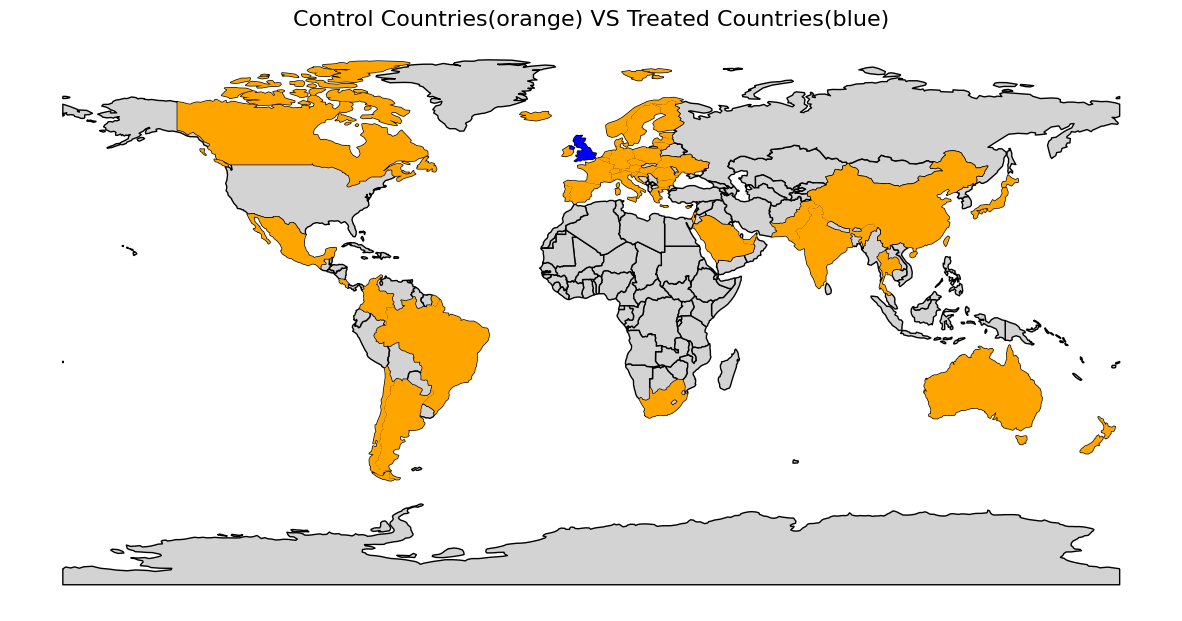

In [3]:
# Reinitialize the required data
import geopandas as gpd
import matplotlib.pyplot as plt

# Load the Natural Earth dataset from a local source or previously downloaded path
# Note: Replace 'path_to_local_data' with the actual path if you have the data locally.
url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url)

# List of countries to highlight
countries_to_highlight = control_countries

# Normalize the country names to uppercase for matching
world['name_upper'] = world['ADMIN'].str.upper()

# Filter for the highlighted countries
highlighted_countries = world[world['name_upper'].isin(countries_to_highlight)]

# Assign colors: UK in blue, others in orange
highlighted_countries['color'] = highlighted_countries['name_upper'].apply(
    lambda x: 'blue' if x == 'UNITED KINGDOM' else 'orange'
)

# Plot the map with the United Kingdom in blue
fig, ax = plt.subplots(figsize=(15, 10))
world.plot(ax=ax, color="lightgrey", edgecolor="black")
highlighted_countries.plot(ax=ax, color=highlighted_countries['color'], legend=True)

# Add title and clean axes
ax.set_title("Control Countries(orange) VS Treated Countries(blue)", fontsize=16)
ax.axis("off")

# Show the plot
plt.show()


### step1: load publication(self data), and align the country names with the country name list in the world bank and filter the control country list from the data list

In [4]:
# publications data
# Pays是国家，里面有一些无效的国家名称，需要清理；Annee_Bibliographique是发表年份；
# pub_total是总发文量；pub_intl是国家合作的文章；Code_Discipline是学科代码；
import pandas as pd
import os
data = pd.read_csv("/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/brexit_experimental_data/publication_counts_merged.csv",encoding='utf-8')
data

,Pays,Annee_Bibliographique,Code_Discipline,pub_total,pub_intl
0,Afghanistan,2005,125,1,0
1,Afghanistan,2005,131,1,1
2,Afghanistan,2005,23,1,1
3,Afghanistan,2005,44,3,2
4,Afghanistan,2005,48,1,1
...,...,...,...,...,...
303761,Zimbabwe,2024,85,4,3
303762,Zimbabwe,2024,88,2,2
303763,Zimbabwe,2024,89,3,3
303764,Zimbabwe,2024,9,1,1


In [2]:
import pandas as pd
import os
base_dir = '/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/publications_raw_data'
article_df = pd.read_csv(os.path.join(base_dir, 'article_brexit.txt'), 
                            sep=',',
                            names=['OST_BK', 'UID', 'Annee_Bibliographique', 'Code_Discipline'],
                            dtype={'OST_BK': str, 'UID': str, 'Annee_Bibliographique': str, 'Code_Discipline': str})
        
print(f"成功读取数据，文章数据共 {len(article_df)} 行")

成功读取数据，文章数据共 32601631 行


In [5]:
# Group by Pays and Annee_Bibliographique, and sum up pub_total and pub_intl
pub_result = data.groupby(['Pays', 'Annee_Bibliographique'], as_index=False)[['pub_total', 'pub_intl']].sum()
pub_result.rename(columns={'Pays': 'Country'}, inplace=True)
pub_result

,Country,Annee_Bibliographique,pub_total,pub_intl
0,Afghanistan,2005,9,7
1,Afghanistan,2006,12,10
2,Afghanistan,2007,11,9
3,Afghanistan,2008,25,23
4,Afghanistan,2009,27,21
...,...,...,...,...
3983,Zimbabwe,2020,750,652
3984,Zimbabwe,2021,901,771
3985,Zimbabwe,2022,832,713
3986,Zimbabwe,2023,749,652


In [6]:
# standard_country_maps = {'CHINA':['PEOPLES-R-CHINA'],'COSTA RICA':['COSTA-RICA'],'IRAN, ISLAMIC REP.':['IRAN'],'KOREA, REP.':['SOUTH-KOREA'],'NEW ZEALAND':['NEW-ZEALAND'],'RUSSIAN FEDERATION':['RUSSIA'],'SAUDI ARABIA':['SAUDI-ARABIA'],'SLOVAK REPUBLIC':['SLOVAKIA'],'SOUTH AFRICA':['SOUTH-AFRICA'],'TURKIYE':['TURKEY'],'UNITED ARAB EMIRATES':['U-ARAB-EMIRATES'],'VIET NAM':['VIETNAM'],'UNITED STATES':['USA'],'UNITED KINGDOM':['ENGLAND','NORTH-IRELAND','SCOTLAND','WALES','_UNITED-KINGDOM','BRITISH-VIRGIN-ISLANDS','BRITISH-WEST-INDIES'],'FRANCE':['FR-POLYNESIA','FRENCH-GUIANA'],'CZECHIA':['CZECH-REPUBLIC']}

standard_country_maps = {'CZECH REPUBLIC':['CZECHIA'],'IRAN':['IRAN, ISLAMIC REP.'],'SOUTH KOREA':['KOREA, REP.'],'RUSSIA':['RUSSIAN FEDERATION'],'SLOVAKIA':['SLOVAK REPUBLIC'],'TURKEY':['TURKIYE'],'VIETNAM':['VIET NAM']}
# workbank country name: ourself country name in web of science


In [7]:
# 使用 standard_country_maps 标准化 pub_result['Country']
# 1) 统一大写与首尾空格
pub_result['Country'] = pub_result['Country'].astype(str).str.upper()

# 2) 替换为标准名
pub_result['Country'] = pub_result['Country'].replace(standard_country_maps)

pub_result

,Country,Annee_Bibliographique,pub_total,pub_intl
0,AFGHANISTAN,2005,9,7
1,AFGHANISTAN,2006,12,10
2,AFGHANISTAN,2007,11,9
3,AFGHANISTAN,2008,25,23
4,AFGHANISTAN,2009,27,21
...,...,...,...,...
3983,ZIMBABWE,2020,750,652
3984,ZIMBABWE,2021,901,771
3985,ZIMBABWE,2022,832,713
3986,ZIMBABWE,2023,749,652


In [8]:
# 仅保留在 control_countries 中的国家（统一大写后匹配）
pub_result = pub_result[pub_result['Country'].isin(control_countries)]
pub_result

,Country,Annee_Bibliographique,pub_total,pub_intl
120,ARGENTINA,2005,5139,2242
121,ARGENTINA,2006,5543,2383
122,ARGENTINA,2007,5947,2596
123,ARGENTINA,2008,6758,2928
124,ARGENTINA,2009,7122,3120
...,...,...,...,...
3922,VIET NAM,2020,12189,9750
3923,VIET NAM,2021,11593,8618
3924,VIET NAM,2022,10158,7115
3925,VIET NAM,2023,9641,6285


In [9]:
# 查看 pub_result 中不在 control_countries 的国家
non_control_countries = control_countries - set(pub_result['Country'])
print('不在 control_countries 的国家数量:', len(non_control_countries))
non_control_countries

不在 control_countries 的国家数量: 0


set()

In [10]:
# Save the final DataFrame to an Excel file

pub_result.to_excel("/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/final_combined_data/first_combined_data.xlsx", index=False)
print("well done!")

well done!


In [1]:
import pandas as pd
pub_result = pd.read_excel("/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/final_combined_data/first_combined_data.xlsx")

In [11]:
# Filter rows where Annee_Bibliographique is between 2005 and 2024 (inclusive)
pub_result = pub_result[(pub_result['Annee_Bibliographique'] >= 2005) & (pub_result['Annee_Bibliographique'] <= 2024)]
pub_result

,Country,Annee_Bibliographique,pub_total,pub_intl
120,ARGENTINA,2005,5139,2242
121,ARGENTINA,2006,5543,2383
122,ARGENTINA,2007,5947,2596
123,ARGENTINA,2008,6758,2928
124,ARGENTINA,2009,7122,3120
...,...,...,...,...
3922,VIET NAM,2020,12189,9750
3923,VIET NAM,2021,11593,8618
3924,VIET NAM,2022,10158,7115
3925,VIET NAM,2023,9641,6285


### step2: load GDP per capita

In [12]:
control_country_GDPS = {}
GDP_file_path = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/GDP per capita/API_NY.GDP.PCAP.CD_DS2_en_excel_v2_130121.xls"

# 稳健读取：自动识别工作表与表头行
xls = pd.ExcelFile(GDP_file_path)
sheet = 'Data' if 'Data' in xls.sheet_names else xls.sheet_names[0]
GDP_data = None

tmp = pd.read_excel(xls, sheet_name=sheet, skiprows=3)
tmp.columns = [str(c).strip() for c in tmp.columns]
if any(c.strip().lower() == 'country name' for c in tmp.columns):
    GDP_data = tmp

if GDP_data is None:
    # 兜底：不跳过行直接读
    GDP_data = pd.read_excel(xls, sheet_name=sheet)
    GDP_data.columns = [str(c).strip() for c in GDP_data.columns]

# 仅删除实际存在的列
cols_to_drop = [c for c in ['Country Code', 'Indicator Name', 'Indicator Code', 'Unnamed: 68'] if c in GDP_data.columns]
GDP_data_cleaned = GDP_data.drop(columns=cols_to_drop)

# 自动定位国家列名（兼容大小写/空格差异）
def _norm(s):
    s = str(s)
    return ''.join(ch.lower() for ch in s if ch.isalnum())
country_col = None
for c in GDP_data_cleaned.columns:
    if _norm(c) in {'countryname', 'country', 'country_nam'} or 'country' in _norm(c):
        country_col = c
        break
if country_col is None:
    # 如果没找到，取首列作为国家列
    country_col = GDP_data_cleaned.columns[0]

# 重塑并标准化列名
GDP_data_cleaned = GDP_data_cleaned.melt(id_vars=[country_col], var_name='Year', value_name='Value')
GDP_data_cleaned = GDP_data_cleaned.rename(columns={country_col: 'Country Name'})
GDP_data_cleaned['Country Name'] = GDP_data_cleaned['Country Name'].str.upper()
GDP_data_cleaned = GDP_data_cleaned.dropna()
GDP_data_cleaned = GDP_data_cleaned.sort_values(by=['Country Name', 'Year'], ascending=[True, True])
GDP_data_cleaned

,Country Name,Year,Value
10642,AFGHANISTAN,2000,174.930991
10908,AFGHANISTAN,2001,138.706822
11174,AFGHANISTAN,2002,178.954088
11440,AFGHANISTAN,2003,198.871116
11706,AFGHANISTAN,2004,221.763654
...,...,...,...
16225,ZIMBABWE,2020,1730.453910
16491,ZIMBABWE,2021,1724.387271
16757,ZIMBABWE,2022,2040.546587
17023,ZIMBABWE,2023,2156.034093


In [13]:
# 确保数据类型一致
pub_result["Annee_Bibliographique"] = pub_result["Annee_Bibliographique"].astype(str)
GDP_data_cleaned["Year"] = GDP_data_cleaned["Year"].astype(str)
# 合并两个表，根据对应关系 country-Country Name 和 Annee_Bibliographique-year
merged_gdp_df = pd.merge(
    pub_result,
    GDP_data_cleaned,
    left_on=["Country", "Annee_Bibliographique"],
    right_on=["Country Name", "Year"],
    how="left"
)
# 重命名列 value 为 gdp_per_capital 并删除多余列
merged_gdp_df = merged_gdp_df.rename(columns={"Value": "gdp_per_capital"}).drop(columns=["Country Name", "Year"])
merged_gdp_df

,Country,Annee_Bibliographique,pub_total,pub_intl,gdp_per_capital
0,ARGENTINA,2005,5139,2242,5067.653423
1,ARGENTINA,2006,5543,2383,5869.380290
2,ARGENTINA,2007,5947,2596,7185.251551
3,ARGENTINA,2008,6758,2928,8944.110266
4,ARGENTINA,2009,7122,3120,8150.235270
...,...,...,...,...,...
1155,VIET NAM,2020,12189,9750,3534.039535
1156,VIET NAM,2021,11593,8618,3704.193559
1157,VIET NAM,2022,10158,7115,4147.697772
1158,VIET NAM,2023,9641,6285,4323.350320


In [14]:
# 找出未能匹配上的国家
unmatched_countries = pub_result.loc[
    ~pub_result["Country"].isin(GDP_data_cleaned["Country Name"])
]
unmatched_countries['Country'].unique()

array(['TAIWAN'], dtype=object)

### load r&d data

In [15]:
control_country_RDE = {}
RDE_file_path = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/Research and developemt expenditure(% of GDP)/API_GB.XPD.RSDV.GD.ZS_DS2_en_excel_v2_129163.xls"
RDE_data = pd.read_excel(RDE_file_path,sheet_name='Data', skiprows=3)

RDE_data_cleaned = RDE_data.drop(columns=['Country Code', 'Indicator Name', 'Indicator Code'])
RDE_data_cleaned

,Country Name,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.03229,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
263,South Africa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.73147,0.74992,0.76257,0.68586,0.61304,0.6024,0.61503,0.61729,NaN,NaN
264,Zambia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
RDE_data_cleaned = RDE_data_cleaned.melt(id_vars=['Country Name'], var_name='Year', value_name='Value') # Reshape the dataframe using melt to get 'Year' and 'Value' columns

RDE_data_cleaned['Country Name'] = RDE_data_cleaned['Country Name'].str.upper() 


In [17]:
RDE_data_cleaned = RDE_data_cleaned.dropna() # Drop rows where Value is NaN
# Sort the data first by 'Country Name' and then by 'Year' in ascending order
RDE_data_cleaned = RDE_data_cleaned.sort_values(by=['Country Name', 'Year'], ascending=[True, True])
RDE_data_cleaned
# print(RDE_data_cleaned[RDE_data_cleaned['Country Name']=='ISRAEL'])

,Country Name,Year,Value
11439,AFRICA EASTERN AND SOUTHERN,2003,0.594540
11705,AFRICA EASTERN AND SOUTHERN,2004,0.626101
11971,AFRICA EASTERN AND SOUTHERN,2005,0.627535
12503,AFRICA EASTERN AND SOUTHERN,2007,0.661792
13301,AFRICA EASTERN AND SOUTHERN,2010,0.586779
...,...,...,...
11436,ZAMBIA,2002,0.005440
11702,ZAMBIA,2003,0.008470
11968,ZAMBIA,2004,0.022230
12234,ZAMBIA,2005,0.024930


In [18]:
# 确保数据类型一致
RDE_data_cleaned["Year"] = RDE_data_cleaned["Year"].astype(str)
# 合并两个表，根据对应关系 country-Country Name 和 Annee_Bibliographique-year
merged_gdp_rde_df = pd.merge(
    merged_gdp_df,
    RDE_data_cleaned,
    left_on=["Country", "Annee_Bibliographique"],
    right_on=["Country Name", "Year"],
    how="left"
)
# 重命名列 value 为 gdp_per_capital 并删除多余列
merged_gdp_rde_df = merged_gdp_rde_df.rename(columns={"Value": "RD"}).drop(columns=["Country Name", "Year"])
merged_gdp_rde_df.rename(columns={'Annee_Bibliographique': 'Year'}, inplace=True)
merged_gdp_rde_df

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398
...,...,...,...,...,...,...
1155,VIET NAM,2020,12189,9750,3534.039535,NaN
1156,VIET NAM,2021,11593,8618,3704.193559,0.42494
1157,VIET NAM,2022,10158,7115,4147.697772,NaN
1158,VIET NAM,2023,9641,6285,4323.350320,NaN


In [19]:
# 找出未能匹配上的国家
unmatched_countries1 = merged_gdp_df.loc[
    ~merged_gdp_df["Country"].isin(RDE_data_cleaned["Country Name"])
]
unmatched_countries1['Country'].unique()

array(['TAIWAN'], dtype=object)

In [20]:
# Save the final DataFrame to an Excel file
output_file = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/final_combined_data/second_combined_data.xlsx"
merged_gdp_rde_df.to_excel(output_file, index=False)
print("well done!")

well done!


### step3: load research personnel from word bank

In [21]:
import pandas as pd
merged_gdp_rde_oecd_unesco_df = pd.read_excel("/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/final_combined_data/second_combined_data.xlsx")
merged_gdp_rde_oecd_unesco_df.head()

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398


In [23]:
import os
control_country_RPW = {}
rpw_file_path = os.path.join("/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/Researchers in R&D (per million people)/API_SP.POP.SCIE.RD.P6_DS2_en_excel_v2_22710.xls")
RPW_data = pd.read_excel(rpw_file_path, sheet_name='Data', skiprows=3)
RPW_data_cleaned = RPW_data.drop(columns=['Country Code', 'Indicator Name', 'Indicator Code'])
RPW_data_cleaned = RPW_data_cleaned.melt(id_vars=['Country Name'], var_name='Year', value_name='Value') # Reshape the dataframe using melt to get 'Year' and 'Value' columns
RPW_data_cleaned['Country Name'] = RPW_data_cleaned['Country Name'].str.upper() # Convert 'Country Name' column to uppercase for case-insensitive matching
RPW_data_cleaned = RPW_data_cleaned.dropna() # Drop rows where Value is NaN
# Sort the data first by 'Country Name' and then by 'Year' in ascending order
RPW_data_cleaned = RPW_data_cleaned.sort_values(by=['Country Name', 'Year'], ascending=[True, True])
RPW_data_cleaned

,Country Name,Year,Value
12773,ALBANIA,2008,155.23568
12030,ALGERIA,2005,170.18968
15222,ALGERIA,2017,821.66519
11183,AMERICAN SAMOA,2002,87.58715
11449,AMERICAN SAMOA,2003,420.77949
...,...,...,...
10106,ZAMBIA,1997,54.29949
10372,ZAMBIA,1998,56.42220
10638,ZAMBIA,1999,55.79382
13032,ZAMBIA,2008,41.90146


In [24]:
# 确保数据类型一致
RPW_data_cleaned["Year"] = RPW_data_cleaned["Year"].astype(int)
# 合并两个表，根据对应关系 country-Country Name 和 Annee_Bibliographique-year
merged_gdp_rde_oecd_unesco_wb_df = pd.merge(
    merged_gdp_rde_oecd_unesco_df,
    RPW_data_cleaned,
    left_on=["Country", "Year"],
    right_on=["Country Name", "Year"],
    how="left"
)
# 重命名列 value 为 gdp_per_capital 并删除多余列
merged_gdp_rde_oecd_unesco_wb_df = merged_gdp_rde_oecd_unesco_wb_df.rename(columns={"Value": "Researchers in RD"}).drop(columns=["Country Name"])
merged_gdp_rde_oecd_unesco_wb_df

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD,Researchers in RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074,816.84120
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216,888.89168
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007,971.29008
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055,1032.67483
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398,1031.64133
...,...,...,...,...,...,...,...
1155,VIET NAM,2020,12189,9750,3534.039535,NaN,NaN
1156,VIET NAM,2021,11593,8618,3704.193559,0.42494,767.88667
1157,VIET NAM,2022,10158,7115,4147.697772,NaN,NaN
1158,VIET NAM,2023,9641,6285,4323.350320,NaN,NaN


In [25]:
# Merge the datasets based on Country and Year
final_file_path = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/final_combined_data/final_combined_data.xlsx"
merged_gdp_rde_oecd_unesco_wb_df.to_excel(final_file_path, index=False)
merged_gdp_rde_oecd_unesco_wb_df

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD,Researchers in RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074,816.84120
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216,888.89168
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007,971.29008
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055,1032.67483
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398,1031.64133
...,...,...,...,...,...,...,...
1155,VIET NAM,2020,12189,9750,3534.039535,NaN,NaN
1156,VIET NAM,2021,11593,8618,3704.193559,0.42494,767.88667
1157,VIET NAM,2022,10158,7115,4147.697772,NaN,NaN
1158,VIET NAM,2023,9641,6285,4323.350320,NaN,NaN


In [26]:
import pandas as pd

stats = merged_gdp_rde_oecd_unesco_wb_df.iloc[:, 2:].agg(['max', 'min','mean','var'])

# Transpose the result for better readability
stats = stats.transpose()
stats

,max,min,mean,var
pub_total,849974.000000,70.00000,36435.069828,6.040442e+09
pub_intl,228087.000000,47.00000,15977.876724,7.470990e+08
gdp_per_capital,137516.587324,710.48808,30942.121108,6.231184e+08
RD,6.019240,0.04230,1.525773,1.113592e+00
Researchers in RD,9434.761300,58.05470,3189.830974,4.500179e+06
